# CMP-L045-0 Mathematics and Statistics for Data Science — Part 1: Applied Problem-Solving Activity

**Dataset:** World Bank, *World Development Indicators* (WDI), DataBank extract, 2015–2022 (last updated 08/10/2026)
**Source:** https://databank.worldbank.org/source/world-development-indicators (licence CC BY-4.0)

This notebook contains all code for the report. Sections follow the assessment brief:

1. Data loading and pre-processing (Task 1 support)
2. Task 2.1 Linear algebra: vectors
3. Task 2.2 Linear algebra: matrices
4. Task 2.3 Descriptive statistics and EDA
5. Task 2.4 Random variables and probability
6. Task 2.5 Interval estimates
7. Summary of outputs used in Task 3 (critical reflection)

Every figure is saved to `figures/` and every result table to `results/` so they can be placed in the report.

## 0. Setup — libraries and output folders

In [1]:
# Core numerical / statistical libraries
import os
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt

# Consistent, print-friendly plotting style for the report
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.family": "serif",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
BLUE, ORANGE, GREY = "#1f5f99", "#d9822b", "#6b6b6b"

# Folders for exported graphs and result tables
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
np.set_printoptions(precision=4, suppress=True)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", stats.__name__)

numpy 2.5.3 | pandas 3.0.5 | scipy scipy.stats


In [2]:
def save_table(df, name, title, fontsize=10):
    # Render a results DataFrame as a PNG (used as a 'screenshot' of results in the report)
    # and save the same table as CSV. Column widths are sized from the text length.
    df.to_csv(f"results/{name}.csv")
    def fmt(v):
        if isinstance(v, (int, np.integer)) or (isinstance(v, float) and float(v).is_integer() and abs(v) < 1e6):
            return f"{int(v):,}"
        if isinstance(v, float):
            return f"{v:,.4f}" if abs(v) < 1e5 else f"{v:.4e}"
        return str(v)
    body = [[fmt(v) for v in row] for row in df.itertuples(index=False)]
    rows = [str(i) for i in df.index]
    header = [""] + [str(c) for c in df.columns]
    cells = [header] + [[r] + b for r, b in zip(rows, body)]
    widths = [max(len(row[j]) for row in cells) * 0.105 + 0.35 for j in range(len(header))]
    W = sum(widths); Hgt = 0.3 * len(cells) + 0.45
    fig, ax = plt.subplots(figsize=(W, Hgt)); ax.axis("off")
    tbl = ax.table(cellText=cells, colWidths=[w / W for w in widths], loc="center", cellLoc="center",
                   bbox=[0, 0, 1, (len(cells) * 0.3) / Hgt])
    tbl.auto_set_font_size(False); tbl.set_fontsize(fontsize)
    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor("#bbbbbb")
        if r == 0 or c == 0:
            cell.set_facecolor("#e8eef5"); cell.set_text_props(weight="bold")
    ax.set_title(title, fontsize=fontsize + 1, weight="bold", loc="left", y=(len(cells) * 0.3) / Hgt)
    fig.savefig(f"results/{name}.png", bbox_inches="tight", pad_inches=0.08)
    plt.close(fig)
    return df

## 1. Data loading and pre-processing

The raw DataBank CSV is in *wide* format: one row per (country, series) and one column per year.
Raw issues handled here:

* missing values are coded as the string `..`;
* five footer lines (blank rows, "Data from database…", "Last Updated…") are appended to the file;
* 266 "countries" include **48 regional / income / lending-group aggregates** (e.g. *World*, *High income*) that must be removed, otherwise countries would be double-counted;
* the data must be reshaped from wide to a long **country–year panel**.

In [3]:
# Load the raw World Bank DataBank extract exactly as downloaded
raw = pd.read_csv("data/raw/WDI_Data_2015_2022.csv")
print("Raw shape:", raw.shape)

# Drop the footer rows (they have no series code)
raw = raw.dropna(subset=["Series Code"])
print("After removing footer rows:", raw.shape)
print("Entities:", raw["Country Code"].nunique(), "| Series:", raw["Series Code"].nunique())
raw.head(3)

Raw shape: (2133, 12)
After removing footer rows: (2128, 12)
Entities: 266 | Series: 8


,Country Name,Country Code,Series Name,Series Code,2015 [YR2015],2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022]
0,Afghanistan,AFG,GDP per capita (current US$),NY.GDP.PCAP.CD,565.569730408751,522.082215583898,525.469770891619,491.337221382603,496.6025042585,510.787063366811,356.496214115892,357.261152798144
1,Afghanistan,AFG,"Life expectancy at birth, female (years)",SP.DYN.LE00.FE.IN,64.178,64.64,65.606,65.942,66.144,64.656,64.079,67.236
2,Afghanistan,AFG,"Life expectancy at birth, male (years)",SP.DYN.LE00.MA.IN,60.363,60.661,59.388,59.175,59.91,58.455,57.052,63.941


In [4]:
# World Bank aggregate codes (regions, income groups, lending groups, World) — not individual countries
AGGREGATES = {
    "AFE","AFW","ARB","CEB","CSS","EAP","EAR","EAS","ECA","ECS","EMU","EUU","FCS","HIC","HPC",
    "IBD","IBT","IDA","IDB","IDX","INX","LAC","LCN","LDC","LIC","LMC","LMY","LTE","MEA","MIC",
    "MNA","NAC","OED","OSS","PRE","PSS","PST","SAS","SSA","SSF","SST","TEA","TEC","TLA","TMN",
    "TSA","TSS","UMC","WLD",
}
present = AGGREGATES & set(raw["Country Code"])
print(f"Aggregates found and removed: {len(present)}")
raw = raw[~raw["Country Code"].isin(AGGREGATES)]
print("Countries kept:", raw["Country Code"].nunique())

Aggregates found and removed: 48
Countries kept: 218


In [5]:
# Short, analysis-friendly names for the 8 series
RENAME = {
    "NY.GDP.PCAP.CD":    "gdp_pc",       # GDP per capita, current US$
    "SP.DYN.LE00.IN":    "life_exp",     # life expectancy at birth, total (years)
    "SP.DYN.LE00.FE.IN": "life_exp_f",   # life expectancy, female
    "SP.DYN.LE00.MA.IN": "life_exp_m",   # life expectancy, male
    "SH.XPD.CHEX.GD.ZS": "health_exp",   # current health expenditure, % of GDP
    "SP.URB.TOTL.IN.ZS": "urban",        # urban population, % of total
    "IT.NET.USER.ZS":    "internet",     # individuals using the Internet, % of population
    "SP.DYN.TFRT.IN":    "fertility",    # births per woman
}

# Wide (years as columns) -> long -> panel (one row per country-year, one column per variable)
year_cols = [c for c in raw.columns if "[YR" in c]
long = raw.melt(id_vars=["Country Name", "Country Code", "Series Code"],
                value_vars=year_cols, var_name="year", value_name="value")
long["year"] = long["year"].str[:4].astype(int)
long["value"] = pd.to_numeric(long["value"].replace("..", np.nan), errors="coerce")  # '..' -> NaN
long["var"] = long["Series Code"].map(RENAME)

panel = (long.set_index(["Country Name", "Country Code", "year", "var"])["value"]
             .unstack("var")                 # one column per variable, missing values kept as NaN
             .reset_index()
             .rename(columns={"Country Name": "country", "Country Code": "code"}))
panel = panel[["country", "code", "year"] + list(RENAME.values())]
panel.columns.name = None
print("Panel shape (rows = country-years):", panel.shape)
panel.to_csv("data/wdi_panel_clean.csv", index=False)
panel.head()

Panel shape (rows = country-years): (1744, 11)


,country,code,year,gdp_pc,life_exp,life_exp_f,life_exp_m,health_exp,urban,internet,fertility
0,Afghanistan,AFG,2015,565.5697,62.2700,64.1780,60.3630,10.1053,24.4649,8.2600,5.6520
1,Afghanistan,AFG,2016,522.0822,62.6460,64.6400,60.6610,11.8186,24.6588,11.0000,5.5420
2,Afghanistan,AFG,2017,525.4698,62.4060,65.6060,59.3880,12.6208,24.8353,13.5000,5.4330
3,Afghanistan,AFG,2018,491.3372,62.4430,65.9420,59.1750,14.2084,24.9992,16.8000,5.3270
4,Afghanistan,AFG,2019,496.6025,62.9410,66.1440,59.9100,14.8313,25.1437,17.6000,5.2380


In [6]:
# Missing-value audit per variable (share of the 1,744 country-years: 218 economies x 8 years)
missing = (panel[list(RENAME.values())].isna().mean() * 100).round(2).to_frame("% missing")
missing["non-missing n"] = panel[list(RENAME.values())].notna().sum()
save_table(missing, "tab0_missing", "Missing values in the country-year panel (2015-2022)")
missing

,% missing,non-missing n
gdp_pc,2.9200,1693
life_exp,0.0000,1744
life_exp_f,0.0000,1744
life_exp_m,0.0000,1744
health_exp,11.3500,1546
urban,0.0000,1744
internet,12.7900,1521
fertility,0.0000,1744


In [7]:
# Cross-section used for most analyses: the latest year (2022).
# A log transform of GDP per capita is added because income is strongly right-skewed (shown in Task 2.3).
df22 = panel[panel["year"] == 2022].copy()
df22["log_gdp"] = np.log(df22["gdp_pc"])

# Self-defined criterion (brief: 'selecting attributes to satisfy self-defined criteria'):
# 'Higher-income' = GDP per capita at or above the 2022 median of all countries with data.
gdp_median = df22["gdp_pc"].median()
df22["income_grp"] = np.where(df22["gdp_pc"] >= gdp_median, "Higher-income", "Lower-income")
df22.loc[df22["gdp_pc"].isna(), "income_grp"] = np.nan
print(f"2022 countries: {len(df22)} | median GDP per capita = US$ {gdp_median:,.0f}")
print(df22["income_grp"].value_counts())

2022 countries: 218 | median GDP per capita = US$ 7,631
income_grp
Lower-income     105
Higher-income    105
Name: count, dtype: int64


## 2. Task 2.1 — Linear algebra: vectors

Each country is one component, so a variable measured across *n* countries is a vector in $\mathbb{R}^n$.
Using the 2022 female and male life expectancy vectors $\mathbf f, \mathbf m$:

* Dot product $\mathbf f\cdot\mathbf m=\sum_i f_i m_i$
* Euclidean norm $\lVert\mathbf f\rVert=\sqrt{\mathbf f\cdot\mathbf f}$
* Cosine similarity $\cos\theta=\dfrac{\mathbf f\cdot\mathbf m}{\lVert\mathbf f\rVert\,\lVert\mathbf m\rVert}$

Raw vectors all lie in the positive orthant, so cosine similarity is inflated by the common level of the data.
After **centering** ($\tilde{\mathbf f}=\mathbf f-\bar f\mathbf 1$) the cosine equals Pearson's correlation $r$, which measures co-movement.

In [8]:
# Vectors: 2022 female and male life expectancy over countries with both values
v = df22[["life_exp_f", "life_exp_m"]].dropna()
f = v["life_exp_f"].to_numpy()
m = v["life_exp_m"].to_numpy()
n = len(f)

dot_fm  = f @ m                       # dot product
norm_f  = np.sqrt(f @ f)              # ||f|| from the definition
norm_m  = np.linalg.norm(m)           # ||m|| with numpy (check)
cos_fm  = dot_fm / (norm_f * norm_m)  # cosine similarity
angle   = np.degrees(np.arccos(cos_fm))

gap     = f - m                       # vector subtraction: female advantage per country
norm_gap = np.linalg.norm(gap)
rms_gap = norm_gap / np.sqrt(n)       # ||g|| / sqrt(n) = root-mean-square gap

fc, mc  = f - f.mean(), m - m.mean()  # centred vectors
cos_c   = (fc @ mc) / (np.linalg.norm(fc) * np.linalg.norm(mc))

print(f"n = {n}")
print(f"f.m = {dot_fm:,.2f}; ||f|| = {norm_f:,.3f}; ||m|| = {norm_m:,.3f}")
print(f"cosine(f, m) = {cos_fm:.5f}  (angle = {angle:.2f} deg)")
print(f"gap g = f - m: mean = {gap.mean():.3f} y, ||g|| = {norm_gap:.3f}, RMS = {rms_gap:.3f}, min = {gap.min():.2f}, max = {gap.max():.2f}")
print(f"cosine of centred vectors = {cos_c:.4f}; Pearson r check = {np.corrcoef(f, m)[0,1]:.4f}")

n = 218
f.m = 1,177,414.33; ||f|| = 1,124.379; ||m|| = 1,047.552
cosine(f, m) = 0.99963  (angle = 1.55 deg)
gap g = f - m: mean = 5.238 y, ||g|| = 82.250, RMS = 5.571, min = 0.39, max = 13.22
cosine of centred vectors = 0.9716; Pearson r check = 0.9716


In [9]:
# Second pair: log GDP per capita vs life expectancy (centred cosine = correlation),
# plus a check of the triangle / Cauchy-Schwarz inequality |x.y| <= ||x|| ||y||
w = df22[["log_gdp", "life_exp"]].dropna()
x = w["log_gdp"].to_numpy() - w["log_gdp"].mean()
y = w["life_exp"].to_numpy() - w["life_exp"].mean()
cos_xy = (x @ y) / (np.linalg.norm(x) * np.linalg.norm(y))
print(f"n = {len(w)}; centred cosine(log GDP, life expectancy) = {cos_xy:.4f}")
print("Cauchy-Schwarz holds:", abs(x @ y) <= np.linalg.norm(x) * np.linalg.norm(y))

vec_tab = pd.DataFrame({
    "Value": [n, dot_fm, norm_f, norm_m, cos_fm, angle, gap.mean(), norm_gap, cos_c, len(w), cos_xy]
}, index=["n (countries)", "Dot product f.m", "||f|| (female)", "||m|| (male)", "Cosine(f, m) raw",
          "Angle (degrees)", "Mean gap f-m (years)", "||f - m||", "Cosine(f, m) centred",
          "n (log GDP, LE)", "Cosine(logGDP, LE) centred"])
save_table(vec_tab, "tab1_vectors", "Task 2.1 Vector operations (2022)")
vec_tab

n = 210; centred cosine(log GDP, life expectancy) = 0.7926
Cauchy-Schwarz holds: True


,Value
n (countries),218.0000
Dot product f.m,"1,177,414.3306"
||f|| (female),"1,124.3791"
||m|| (male),"1,047.5521"
"Cosine(f, m) raw",0.9996
Angle (degrees),1.5507
Mean gap f-m (years),5.2384
||f - m||,82.2503
"Cosine(f, m) centred",0.9716
"n (log GDP, LE)",210.0000


## 3. Task 2.2 — Linear algebra: matrices

**Data matrix.** $X\in\mathbb{R}^{n\times p}$ with one row per country (2022, complete cases) and $p=6$ columns:
log GDP per capita, life expectancy, health expenditure, urbanisation, internet use, fertility.

**Pre-processing with matrix operations.**
Centering matrix $H=I_n-\tfrac1n\mathbf 1\mathbf 1^\top$ gives $X_c=HX$ (column means become 0).
Scaling matrix $D=\operatorname{diag}(s_1,\dots,s_p)$ gives the standardised matrix $Z=X_cD^{-1}$.

**Gram matrix.** $X^\top X$ (p×p) holds sums of squares on the diagonal and cross-products off the diagonal.
For standardised data $\tfrac1{n-1}Z^\top Z=R$, the correlation matrix.

**Determinant.** $\det R=\prod_k\lambda_k\in[0,1]$. Values near 0 mean the columns are close to linearly dependent
(multicollinearity), so $(X^\top X)^{-1}$ in the normal equations $\hat\beta=(X^\top X)^{-1}X^\top y$ becomes unstable.

In [10]:
# Build the data matrix X (2022, complete cases)
cols = ["log_gdp", "life_exp", "health_exp", "urban", "internet", "fertility"]
Xdf = df22.dropna(subset=cols)[["country"] + cols].set_index("country")
X = Xdf.to_numpy()
n, p = X.shape
print(f"X is {n} x {p} (countries x variables)")
print("First 3 rows of X:\n", X[:3])

X is 177 x 6 (countries x variables)
First 3 rows of X:
 [[ 5.8785 65.617  23.0882 25.3939 15.8663  4.932 ]
 [ 8.9563 78.769   7.5365 57.8643 82.6137  1.355 ]
 [ 8.5092 76.129   3.6346 74.1796 74.7815  2.817 ]]


In [11]:
# Matrix pre-processing: centering matrix H and scaling matrix D^-1
ones = np.ones((n, 1))
H = np.eye(n) - (ones @ ones.T) / n          # n x n centering matrix (symmetric, idempotent)
Xc = H @ X                                    # centred data
s = np.sqrt(np.diag(Xc.T @ Xc) / (n - 1))     # column standard deviations from the Gram matrix
D_inv = np.diag(1 / s)
Z = Xc @ D_inv                                # standardised (z-score) data

print("H idempotent (H @ H == H):", np.allclose(H @ H, H))
print("Column means of Z (~0):", Z.mean(axis=0).round(10))
print("Column SDs of Z (=1):", Z.std(axis=0, ddof=1).round(6))

# Min-max scaling is also an affine matrix transform: X_mm = (X - 1 min^T) diag(1/range)
mins, rng = X.min(axis=0), X.max(axis=0) - X.min(axis=0)
X_mm = (X - ones @ mins[None, :]) @ np.diag(1 / rng)
print("Min-max range check:", X_mm.min(axis=0).round(3), X_mm.max(axis=0).round(3))

H idempotent (H @ H == H): True
Column means of Z (~0): [0. 0. 0. 0. 0. 0.]
Column SDs of Z (=1): [1. 1. 1. 1. 1. 1.]
Min-max range check: [0. 0. 0. 0. 0. 0.] [1. 1. 1. 1. 1. 1.]


In [12]:
# Gram matrix X^T X on the raw data, and its standardised version (correlation matrix)
XtX = X.T @ X
R = (Z.T @ Z) / (n - 1)
print("Symmetric:", np.allclose(XtX, XtX.T), "| R equals np.corrcoef:", np.allclose(R, np.corrcoef(X, rowvar=False)))

xtx_tab = pd.DataFrame(XtX, index=cols, columns=cols)
r_tab = pd.DataFrame(R, index=cols, columns=cols)
save_table(xtx_tab, "tab2a_XtX", r"$X^TX$ for the raw 2022 data matrix (sums of squares / cross-products)", fontsize=9)
save_table(r_tab, "tab2b_corr", r"$R = Z^TZ/(n-1)$: correlation matrix of standardised data")
r_tab

Symmetric: True | R equals np.corrcoef: True


,log_gdp,life_exp,health_exp,urban,internet,fertility
log_gdp,1.0000,0.7924,0.2097,0.6373,0.8574,-0.7745
life_exp,0.7924,1.0000,0.1634,0.5278,0.7773,-0.8034
health_exp,0.2097,0.1634,1.0000,0.2336,0.1924,-0.2101
urban,0.6373,0.5278,0.2336,1.0000,0.6946,-0.4827
internet,0.8574,0.7773,0.1924,0.6946,1.0000,-0.8374
fertility,-0.7745,-0.8034,-0.2101,-0.4827,-0.8374,1.0000


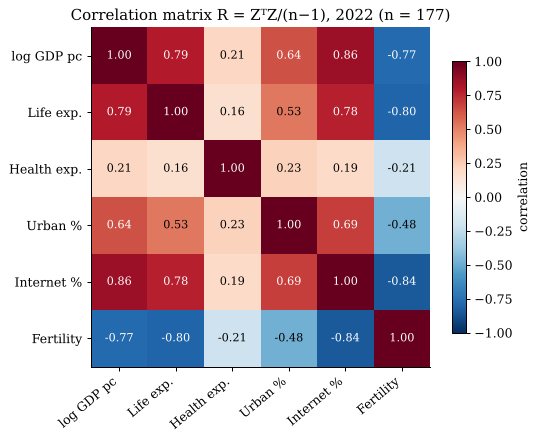

In [13]:
# Heat-map of R (interpretation of Z^T Z)
fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(R, cmap="RdBu_r", vmin=-1, vmax=1)
labels = ["log GDP pc", "Life exp.", "Health exp.", "Urban %", "Internet %", "Fertility"]
ax.set_xticks(range(p)); ax.set_xticklabels(labels, rotation=40, ha="right")
ax.set_yticks(range(p)); ax.set_yticklabels(labels)
ax.grid(False)
for i in range(p):
    for j in range(p):
        ax.text(j, i, f"{R[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(R[i, j]) > 0.6 else "black", fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.8, label="correlation")
ax.set_title(f"Correlation matrix R = ZᵀZ/(n−1), 2022 (n = {n})")
fig.tight_layout(); fig.savefig("figures/fig5_correlation_matrix.png"); plt.show()

In [14]:
# Determinant-based analysis
det_XtX = np.linalg.det(XtX)
sign, logdet = np.linalg.slogdet(XtX)        # stable log-determinant
det_R = np.linalg.det(R)
eig = np.linalg.eigvalsh(R)[::-1]            # eigenvalues of R, descending
cond_R = eig.max() / eig.min()

# det(R) = product of eigenvalues (check) and share of variance on the first component
print(f"det(X^T X) = {det_XtX:.4e} (log = {logdet:.3f}) — scale dependent, hard to interpret")
print(f"det(R) = {det_R:.5f}; product of eigenvalues = {np.prod(eig):.5f}")
print("Eigenvalues of R:", eig.round(4), "| first PC explains", f"{eig[0]/p:.1%}")
print(f"Condition number of R = {cond_R:.2f}")

# 2x2 sub-determinants: det = 1 - r^2 = share of 'non-shared' variation for a pair
pairs = [("log_gdp", "internet"), ("life_exp", "fertility"), ("log_gdp", "health_exp")]
for a, b in pairs:
    i, j = cols.index(a), cols.index(b)
    sub = R[np.ix_([i, j], [i, j])]
    print(f"det R[{a}, {b}] = {np.linalg.det(sub):.4f}  (r = {R[i, j]:.3f})")

# Variance inflation factors: diagonal of R^{-1}
R_inv = np.linalg.inv(R)
vif = pd.Series(np.diag(R_inv), index=cols)
print("VIF = diag(R^-1):\n", vif.round(3).to_string())

det(X^T X) = 7.4744e+22 (log = 52.668) — scale dependent, hard to interpret
det(R) = 0.00924; product of eigenvalues = 0.00924
Eigenvalues of R: [3.9648 0.9463 0.5738 0.2203 0.1948 0.1   ] | first PC explains 66.1%
Condition number of R = 39.63
det R[log_gdp, internet] = 0.2649  (r = 0.857)
det R[life_exp, fertility] = 0.3545  (r = -0.803)
det R[log_gdp, health_exp] = 0.9560  (r = 0.210)
VIF = diag(R^-1):
 log_gdp      4.5700
life_exp     3.5770
health_exp   1.0840
urban        2.1880
internet     6.7120
fertility    4.5900


In [15]:
# Practical consequence: least-squares via the normal equations beta = (A^T A)^{-1} A^T y
# predicting life expectancy from the other five standardised variables
y = Z[:, cols.index("life_exp")]
A = np.column_stack([np.ones(n), np.delete(Z, cols.index("life_exp"), axis=1)])
AtA = A.T @ A
beta = np.linalg.solve(AtA, A.T @ y)            # solve rather than invert, for numerical stability
resid = y - A @ beta
r2 = 1 - (resid @ resid) / (y @ y)
print(f"det(A^T A / n) = {np.linalg.det(AtA / n):.4f}")
beta_s = pd.Series(beta, index=["intercept"] + [c for c in cols if c != "life_exp"])
print("Standardised coefficients:\n", beta_s.round(4).to_string())
print(f"R^2 = {r2:.4f}")

mat_tab = pd.DataFrame({"Value": [n, p, logdet, det_R, eig[0], eig[-1], eig[0] / p, cond_R,
                                   vif.max(), r2]},
                       index=["n (rows of X)", "p (columns)", r"log det($X^TX$)", "det(R)",
                              "Largest eigenvalue of R", "Smallest eigenvalue of R",
                              "Share of variance, 1st PC", "Condition number of R",
                              f"Max VIF ({vif.idxmax()})", "R² (normal equations)"])
eig_tab = pd.DataFrame({"eigenvalue": eig, "share": eig / p, "VIF (by variable)": vif.values},
                       index=[f"λ{k+1} / {c}" for k, c in enumerate(cols)])
save_table(mat_tab, "tab2c_determinant", "Task 2.2 Determinant and eigen analysis (2022)")
save_table(beta_s.to_frame("β (standardised)"), "tab2d_normal_eq",
           "Normal equations: life expectancy on 5 predictors")
mat_tab

det(A^T A / n) = 0.0321
Standardised coefficients:
 intercept     0.0000
log_gdp       0.3767
health_exp   -0.0304
urban         0.0393
internet      0.0502
fertility    -0.4570
R^2 = 0.7205


,Value
n (rows of X),177.0000
p (columns),6.0000
log det($X^TX$),52.6684
det(R),0.0092
Largest eigenvalue of R,3.9648
Smallest eigenvalue of R,0.1000
"Share of variance, 1st PC",0.6608
Condition number of R,39.6310
Max VIF (internet),6.7120
R² (normal equations),0.7205


## 4. Task 2.3 — Descriptive statistics and EDA

Key variables: **life expectancy** and **GDP per capita** (2022). Formulas implemented by hand and checked with SciPy:

$\bar x=\frac1n\sum x_i,\qquad s^2=\frac1{n-1}\sum (x_i-\bar x)^2,\qquad
g_1=\frac{\frac1n\sum(x_i-\bar x)^3}{\left(\frac1n\sum(x_i-\bar x)^2\right)^{3/2}},\qquad
g_2=\frac{\frac1n\sum(x_i-\bar x)^4}{\left(\frac1n\sum(x_i-\bar x)^2\right)^{2}}-3$

($g_2$ is excess kurtosis: 0 for a normal distribution.)

In [16]:
def describe_by_hand(x):
    # Moment-based summary statistics implemented from the formulas above
    x = np.asarray(x, dtype=float); x = x[~np.isnan(x)]
    n = len(x); mean = x.sum() / n; d = x - mean
    m2, m3, m4 = (d**2).mean(), (d**3).mean(), (d**4).mean()
    return {"n": n, "mean": mean, "median": np.median(x), "variance (s²)": (d**2).sum() / (n - 1),
            "std dev (s)": np.sqrt((d**2).sum() / (n - 1)), "skewness g1": m3 / m2**1.5,
            "excess kurtosis g2": m4 / m2**2 - 3, "min": x.min(), "max": x.max()}

desc = pd.DataFrame({
    "Life expectancy (years)": describe_by_hand(df22["life_exp"]),
    "GDP per capita (US$)": describe_by_hand(df22["gdp_pc"]),
    "log GDP per capita": describe_by_hand(df22["log_gdp"]),
})
# Check against SciPy (biased moment estimators, same as the formulas above)
for c, col in [("Life expectancy (years)", "life_exp"), ("GDP per capita (US$)", "gdp_pc")]:
    x = df22[col].dropna()
    assert np.isclose(desc.loc["skewness g1", c], stats.skew(x))
    assert np.isclose(desc.loc["excess kurtosis g2", c], stats.kurtosis(x))
print("Hand-computed skewness and kurtosis match scipy.stats")
# Outlier sensitivity: Central African Republic reports LE = 18.8 years in 2022 (a crisis-year life-table value in WDI)
le_wo = df22.loc[df22["code"] != "CAF", "life_exp"]
print(f"Without CAF: skewness = {stats.skew(le_wo):.3f}, excess kurtosis = {stats.kurtosis(le_wo):.3f}")
desc["LE excl. CAF"] = describe_by_hand(le_wo)
save_table(desc, "tab3_descriptives", "Task 2.3 Summary statistics, 2022")
desc

Hand-computed skewness and kurtosis match scipy.stats
Without CAF: skewness = -0.449, excess kurtosis = -0.464


,Life expectancy (years),GDP per capita (US$),log GDP per capita,LE excl. CAF
n,218.0000,210.0000,210.0000,217.0000
mean,73.0654,"21,109.8625",9.0250,73.3154
median,74.1860,"7,630.9159",8.9400,74.2110
variance (s²),63.1713,"966,269,691.2706",2.1523,49.7770
std dev (s),7.9480,"31,084.8788",1.4671,7.0553
skewness g1,-1.7069,3.0455,-0.0431,-0.4489
excess kurtosis g2,8.5790,12.7625,-0.8423,-0.4641
min,18.8180,301.8323,5.7099,53.9310
max,85.7460,"226,052.0607",12.3285,85.7460


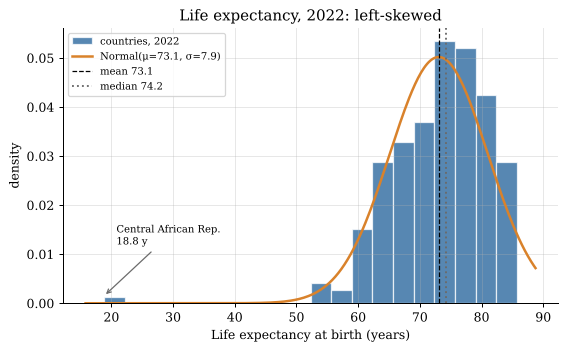

In [17]:
# Figure 1: histogram of life expectancy with fitted normal density
le = df22["life_exp"].dropna()
mu, sd = le.mean(), le.std(ddof=1)
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.hist(le, bins=20, density=True, color=BLUE, alpha=0.75, edgecolor="white", label="countries, 2022")
grid = np.linspace(le.min() - 3, le.max() + 3, 300)
ax.plot(grid, stats.norm.pdf(grid, mu, sd), color=ORANGE, lw=2, label=f"Normal(μ={mu:.1f}, σ={sd:.1f})")
ax.axvline(le.mean(), color="k", ls="--", lw=1, label=f"mean {le.mean():.1f}")
ax.axvline(le.median(), color=GREY, ls=":", lw=1.5, label=f"median {le.median():.1f}")
ax.set_xlabel("Life expectancy at birth (years)"); ax.set_ylabel("density")
ax.set_title("Life expectancy, 2022: left-skewed")
caf = df22.loc[df22["code"] == "CAF", "life_exp"].iloc[0]
ax.annotate(f"Central African Rep.\n{caf:.1f} y", xy=(caf, 0.0015), xytext=(caf + 2, 0.012),
            fontsize=8, arrowprops=dict(arrowstyle="->", color=GREY))
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig("figures/fig1_hist_life_expectancy.png"); plt.show()

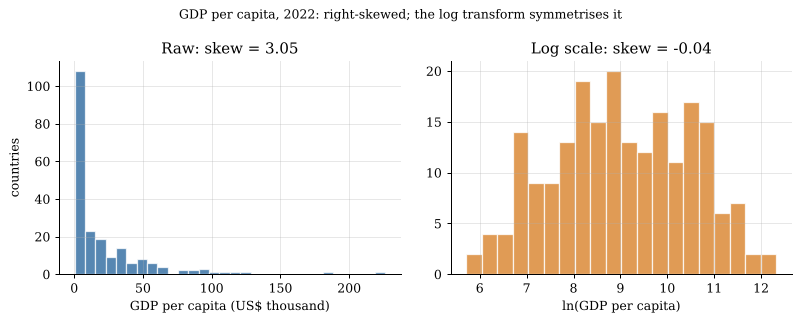

In [18]:
# Figure 2: GDP per capita on the raw and log scale
g = df22["gdp_pc"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].hist(g / 1000, bins=30, color=BLUE, alpha=0.75, edgecolor="white")
axes[0].set_xlabel("GDP per capita (US$ thousand)"); axes[0].set_ylabel("countries")
axes[0].set_title(f"Raw: skew = {stats.skew(g):.2f}")
axes[1].hist(np.log(g), bins=20, color=ORANGE, alpha=0.8, edgecolor="white")
axes[1].set_xlabel("ln(GDP per capita)")
axes[1].set_title(f"Log scale: skew = {stats.skew(np.log(g)):.2f}")
fig.suptitle("GDP per capita, 2022: right-skewed; the log transform symmetrises it", fontsize=10)
fig.tight_layout(); fig.savefig("figures/fig2_hist_gdp_raw_vs_log.png"); plt.show()

Each 1% higher GDP pc ~ 0.043 more years; doubling GDP pc ~ 2.98 years


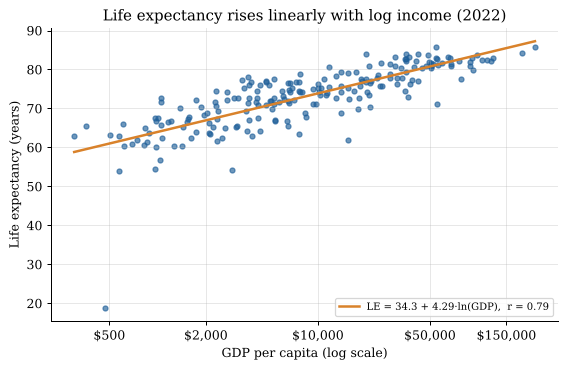

In [19]:
# Figure 3: scatterplot of life expectancy against log GDP with least-squares line
sc = df22[["log_gdp", "life_exp", "gdp_pc"]].dropna()
slope, intercept, r, pval, se = stats.linregress(sc["log_gdp"], sc["life_exp"])
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.scatter(sc["log_gdp"], sc["life_exp"], s=16, color=BLUE, alpha=0.65)
xs = np.linspace(sc["log_gdp"].min(), sc["log_gdp"].max(), 50)
ax.plot(xs, intercept + slope * xs, color=ORANGE, lw=2,
        label=f"LE = {intercept:.1f} + {slope:.2f}·ln(GDP),  r = {r:.2f}")
ticks = [500, 2000, 10000, 50000, 150000]
ax.set_xticks(np.log(ticks)); ax.set_xticklabels([f"${t:,}" for t in ticks])
ax.set_xlabel("GDP per capita (log scale)"); ax.set_ylabel("Life expectancy (years)")
ax.set_title("Life expectancy rises linearly with log income (2022)")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig("figures/fig3_scatter_loggdp_life_exp.png"); plt.show()
print(f"Each 1% higher GDP pc ~ {slope/100:.3f} more years; doubling GDP pc ~ {slope*np.log(2):.2f} years")

Lower-income: n=105, Q1=64.2, median=67.8, Q3=72.6, IQR=8.4, outliers=1
Higher-income: n=105, Q1=75.2, median=78.5, Q3=81.7, IQR=6.6, outliers=1


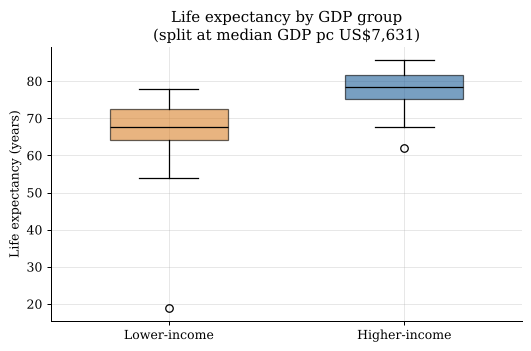

In [20]:
# Figure 4: boxplots of life expectancy by self-defined income group, with IQR / outlier fences
grp = df22.dropna(subset=["life_exp", "income_grp"])
data = [grp.loc[grp["income_grp"] == k, "life_exp"] for k in ["Lower-income", "Higher-income"]]
fig, ax = plt.subplots(figsize=(6.0, 4))
bp = ax.boxplot(data, patch_artist=True, widths=0.5, medianprops=dict(color="k"))
ax.set_xticks([1, 2]); ax.set_xticklabels(["Lower-income", "Higher-income"])
for patch, col in zip(bp["boxes"], [ORANGE, BLUE]):
    patch.set_facecolor(col); patch.set_alpha(0.6)
ax.set_ylabel("Life expectancy (years)")
ax.set_title(f"Life expectancy by GDP group\n(split at median GDP pc US${gdp_median:,.0f})")
fig.tight_layout(); fig.savefig("figures/fig4_boxplot_life_exp_by_group.png"); plt.show()

for k, d in zip(["Lower-income", "Higher-income"], data):
    q1, q3 = np.percentile(d, [25, 75]); iqr = q3 - q1
    outl = d[(d < q1 - 1.5 * iqr) | (d > q3 + 1.5 * iqr)]
    print(f"{k}: n={len(d)}, Q1={q1:.1f}, median={d.median():.1f}, Q3={q3:.1f}, IQR={iqr:.1f}, outliers={len(outl)}")

## 5. Task 2.4 — Random variables and probability

**Discrete random variable.** $K$ = number of the seven year-on-year changes (2015→2016, …, 2021→2022) in which a
country's life expectancy **increased**, $K\in\{0,1,\dots,7\}$. Empirical PMF $\hat p(k)=\#\{K=k\}/N$.
If the yearly changes were independent with common probability $p$, then $K\sim\text{Binomial}(7,p)$ with
$P(K=k)=\binom7k p^k(1-p)^{7-k}$, $E[K]=7p$, $\operatorname{Var}(K)=7p(1-p)$.

**Continuous random variable.** Life expectancy $L$ (2022) modelled as $L\sim N(\mu,\sigma^2)$ with $\hat\mu=\bar x$, $\hat\sigma=s$:
$P(a<L<b)=\Phi\!\left(\frac{b-\mu}\sigma\right)-\Phi\!\left(\frac{a-\mu}\sigma\right)$, compared with empirical relative frequencies.
GDP per capita is modelled as **log-normal**: $\ln G\sim N(\mu_{\ln},\sigma^2_{\ln})$.

In [21]:
# Discrete RV: K = number of yearly increases in life expectancy, 2015-2022
wide_le = panel.pivot(index="code", columns="year", values="life_exp").dropna()
inc = (wide_le.diff(axis=1).iloc[:, 1:] > 0)     # 7 Bernoulli trials per country
K = inc.sum(axis=1).astype(int)
N = len(K)

pmf_emp = K.value_counts().reindex(range(8), fill_value=0) / N
p_hat = inc.to_numpy().mean()                    # pooled probability of an increase
pmf_bin = stats.binom.pmf(range(8), 7, p_hat)

EK, VarK = (np.arange(8) * pmf_emp).sum(), K.var(ddof=0)
print(f"N = {N} countries; p_hat = {p_hat:.4f}")
print(f"Empirical E[K] = {EK:.3f}, Var[K] = {VarK:.3f}")
print(f"Binomial  E[K] = {7*p_hat:.3f}, Var[K] = {7*p_hat*(1-p_hat):.3f}")
print("Share of increases by year-pair:\n", inc.mean().round(3).to_string())

prob_disc = pd.DataFrame({"empirical P(K=k)": pmf_emp.values, "Binomial(7, p̂)": pmf_bin}, index=[f"k = {k}" for k in range(8)])
prob_disc.loc["P(K = 7)"] = [pmf_emp[7], pmf_bin[7]]
prob_disc.loc["P(K ≤ 4)"] = [pmf_emp[:5].sum(), stats.binom.cdf(4, 7, p_hat)]
prob_disc.loc["E[K]"] = [EK, 7 * p_hat]
prob_disc.loc["Var[K]"] = [VarK, 7 * p_hat * (1 - p_hat)]
save_table(prob_disc, "tab4a_discrete", f"Task 2.4 Discrete RV K (N = {N}, p̂ = {p_hat:.3f})")
prob_disc

N = 218 countries; p_hat = 0.6927
Empirical E[K] = 4.849, Var[K] = 1.495
Binomial  E[K] = 4.849, Var[K] = 1.490
Share of increases by year-pair:
 year
2016   0.8440
2017   0.8120
2018   0.8810
2019   0.8580
2020   0.2980
2021   0.2800
2022   0.8760


,empirical P(K=k),"Binomial(7, p̂)"
k = 0,0.0000,0.0003
k = 1,0.0092,0.0041
k = 2,0.0275,0.0276
k = 3,0.1101,0.1038
k = 4,0.1835,0.2339
k = 5,0.3624,0.3163
k = 6,0.2431,0.2376
k = 7,0.0642,0.0765
P(K = 7),0.0642,0.0765
P(K ≤ 4),0.3303,0.3696


Chi-square = 4.49, df = 3, p-value = 2.13e-01


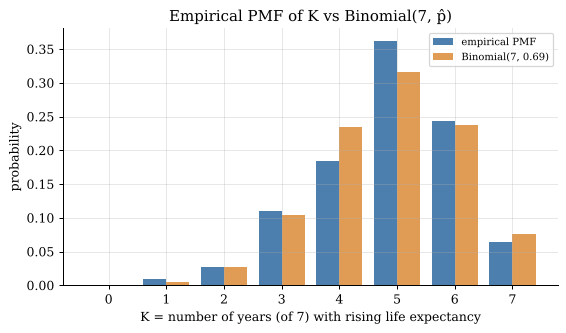

In [22]:
# Figure 6: empirical PMF vs binomial model
fig, ax = plt.subplots(figsize=(6.4, 3.8))
k = np.arange(8)
ax.bar(k - 0.2, pmf_emp.values, width=0.4, color=BLUE, alpha=0.8, label="empirical PMF")
ax.bar(k + 0.2, pmf_bin, width=0.4, color=ORANGE, alpha=0.8, label=f"Binomial(7, {p_hat:.2f})")
ax.set_xticks(k); ax.set_xlabel("K = number of years (of 7) with rising life expectancy")
ax.set_ylabel("probability")
ax.set_title("Empirical PMF of K vs Binomial(7, p̂)")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("figures/fig6_pmf_discrete.png"); plt.show()

# Goodness of fit: chi-square on pooled cells (K<=3, 4, 5, 6, 7) to keep expected counts >= 5
obs = np.array([pmf_emp[:4].sum(), *pmf_emp[4:]]) * N
exp = np.array([pmf_bin[:4].sum(), *pmf_bin[4:]]) * N
chi2 = ((obs - exp) ** 2 / exp).sum(); dfree = len(obs) - 1 - 1   # minus 1 estimated parameter
print(f"Chi-square = {chi2:.2f}, df = {dfree}, p-value = {stats.chi2.sf(chi2, dfree):.2e}")

In [23]:
# Continuous RV: life expectancy ~ Normal(mu, sigma); compare model and empirical probabilities
le = df22["life_exp"].dropna(); mu, sd = le.mean(), le.std(ddof=1)
events = {
    "P(L > 80)":      (lambda x: x > 80,               1 - stats.norm.cdf(80, mu, sd)),
    "P(L < 60)":      (lambda x: x < 60,               stats.norm.cdf(60, mu, sd)),
    "P(65 < L < 75)": (lambda x: (x > 65) & (x < 75),  stats.norm.cdf(75, mu, sd) - stats.norm.cdf(65, mu, sd)),
    "P(|L-μ| < σ)":   (lambda x: abs(x - mu) < sd,     stats.norm.cdf(1) - stats.norm.cdf(-1)),
}
rows = {k: [ev(le).mean(), model] for k, (ev, model) in events.items()}

# Log-normal model for GDP per capita
lg = df22["log_gdp"].dropna(); mu_l, sd_l = lg.mean(), lg.std(ddof=1)
gdp = df22["gdp_pc"].dropna()
rows["P(GDP pc > $20,000)"] = [(gdp > 20000).mean(), 1 - stats.norm.cdf(np.log(20000), mu_l, sd_l)]
rows["P(GDP pc < $1,500)"]  = [(gdp < 1500).mean(),  stats.norm.cdf(np.log(1500), mu_l, sd_l)]
prob_cont = pd.DataFrame(rows, index=["empirical", "model"]).T
prob_cont["difference"] = prob_cont["model"] - prob_cont["empirical"]

# z-score working for one event, shown explicitly
z80 = (80 - mu) / sd
print(f"L ~ N({mu:.3f}, {sd:.3f}^2): z = (80 - {mu:.2f}) / {sd:.2f} = {z80:.3f}; P(L > 80) = 1 - Φ({z80:.3f}) = {1 - stats.norm.cdf(z80):.4f}")
print(f"ln(GDP) ~ N({mu_l:.3f}, {sd_l:.3f}^2)")
# Normality diagnostics (Shapiro-Wilk)
print("Shapiro-Wilk p-values: life_exp =", f"{stats.shapiro(le).pvalue:.2e}", "| log GDP =", f"{stats.shapiro(lg).pvalue:.3f}")
save_table(prob_cont, "tab4b_continuous", "Task 2.4 Continuous RVs: model vs empirical probabilities (2022)")
prob_cont

L ~ N(73.065, 7.948^2): z = (80 - 73.07) / 7.95 = 0.872; P(L > 80) = 1 - Φ(0.872) = 0.1915
ln(GDP) ~ N(9.025, 1.467^2)
Shapiro-Wilk p-values: life_exp = 4.01e-11 | log GDP = 0.015


,empirical,model,difference
P(L > 80),0.2156,0.1915,-0.0241
P(L < 60),0.0275,0.0501,0.0226
P(65 < L < 75),0.4037,0.4410,0.0374
P(|L-μ| < σ),0.6927,0.6827,-0.0100
"P(GDP pc > $20,000)",0.3286,0.2747,-0.0539
"P(GDP pc < $1,500)",0.1429,0.1216,-0.0212


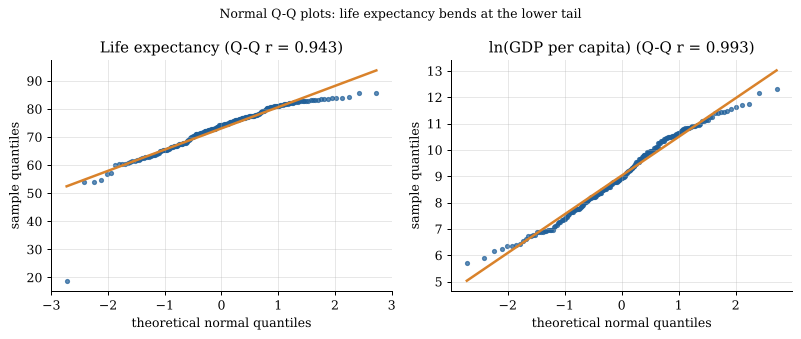

In [24]:
# Figure 7: normal Q-Q plots — life expectancy vs log GDP
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, series, title in [(axes[0], le, "Life expectancy"), (axes[1], lg, "ln(GDP per capita)")]:
    (osm, osr), (sl, ic, rr) = stats.probplot(series, dist="norm")
    ax.scatter(osm, osr, s=10, color=BLUE, alpha=0.7)
    ax.plot(osm, sl * osm + ic, color=ORANGE, lw=2)
    ax.set_xlabel("theoretical normal quantiles"); ax.set_ylabel("sample quantiles")
    ax.set_title(f"{title} (Q-Q r = {rr:.3f})")
fig.suptitle("Normal Q-Q plots: life expectancy bends at the lower tail", fontsize=10)
fig.tight_layout(); fig.savefig("figures/fig7_qq_plots.png"); plt.show()

## 6. Task 2.5 — Interval estimates (95%)

| Interval | Formula |
|---|---|
| one-sample mean | $\bar x\pm t_{0.975,\,n-1}\,s/\sqrt n$ |
| one-sample proportion (Wald) | $\hat p\pm z_{0.975}\sqrt{\hat p(1-\hat p)/n}$ |
| two-sample mean difference (Welch) | $(\bar x_1-\bar x_2)\pm t_{0.975,\,\nu}\sqrt{s_1^2/n_1+s_2^2/n_2}$, Welch–Satterthwaite $\nu$ |
| two-sample proportion difference | $(\hat p_1-\hat p_2)\pm z_{0.975}\sqrt{\hat p_1(1-\hat p_1)/n_1+\hat p_2(1-\hat p_2)/n_2}$ |

Definitions used (2022):
* mean: life expectancy of all countries;
* proportion: share of countries with **internet use ≥ 75%** of the population;
* two means: life expectancy, Higher-income vs Lower-income group (median GDP split);
* two proportions: share of countries spending **≥ 6% of GDP on health**, Higher- vs Lower-income.

In [25]:
z = stats.norm.ppf(0.975)
ci_rows = {}

# (1) One-sample mean: life expectancy
x = df22["life_exp"].dropna(); n1 = len(x)
t1 = stats.t.ppf(0.975, n1 - 1); se1 = x.std(ddof=1) / np.sqrt(n1)
ci_rows["Mean life expectancy (years)"] = [n1, x.mean(), se1, t1, x.mean() - t1 * se1, x.mean() + t1 * se1]
print(f"(1) xbar = {x.mean():.3f}, s = {x.std(ddof=1):.3f}, n = {n1}, SE = {se1:.4f}, t = {t1:.4f}")

# (2) One-sample proportion: internet >= 75%
it = df22["internet"].dropna(); n2 = len(it); x2 = int((it >= 75).sum()); ph = x2 / n2
se2 = np.sqrt(ph * (1 - ph) / n2)
ci_rows["Proportion internet ≥ 75%"] = [n2, ph, se2, z, ph - z * se2, ph + z * se2]
print(f"(2) x = {x2}, n = {n2}, p_hat = {ph:.4f}, SE = {se2:.4f}; checks n*p = {n2*ph:.0f}, n*(1-p) = {n2*(1-ph):.0f}")

# (3) Two-sample mean difference (Welch): life expectancy, Higher - Lower income
a = df22.loc[df22["income_grp"] == "Higher-income", "life_exp"].dropna()
b = df22.loc[df22["income_grp"] == "Lower-income", "life_exp"].dropna()
va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
se3 = np.sqrt(va + vb)
nu = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))   # Welch-Satterthwaite df
t3 = stats.t.ppf(0.975, nu); d3 = a.mean() - b.mean()
ci_rows["Mean LE: Higher − Lower income"] = [len(a) + len(b), d3, se3, t3, d3 - t3 * se3, d3 + t3 * se3]
print(f"(3) means {a.mean():.3f} (n={len(a)}) vs {b.mean():.3f} (n={len(b)}); SE = {se3:.4f}; Welch df = {nu:.1f}")

# (4) Two-sample proportion difference: health expenditure >= 6% of GDP, Higher - Lower income
h = df22.dropna(subset=["health_exp", "income_grp"])
hA = h.loc[h["income_grp"] == "Higher-income", "health_exp"] >= 6
hB = h.loc[h["income_grp"] == "Lower-income", "health_exp"] >= 6
pA, pB = hA.mean(), hB.mean()
se4 = np.sqrt(pA * (1 - pA) / len(hA) + pB * (1 - pB) / len(hB)); d4 = pA - pB
ci_rows["Prop. health exp ≥ 6%: Higher − Lower"] = [len(hA) + len(hB), d4, se4, z, d4 - z * se4, d4 + z * se4]
print(f"(4) p1 = {pA:.4f} ({hA.sum()}/{len(hA)}) vs p2 = {pB:.4f} ({hB.sum()}/{len(hB)}); SE = {se4:.4f}")

ci = pd.DataFrame(ci_rows, index=["n", "estimate", "std. error", "critical value", "95% lower", "95% upper"]).T
ci["n"] = ci["n"].astype(int)
save_table(ci, "tab5_confidence_intervals", "Task 2.5 95% confidence intervals (2022)")
ci

(1) xbar = 73.065, s = 7.948, n = 218, SE = 0.5383, t = 1.9710
(2) x = 104, n = 182, p_hat = 0.5714, SE = 0.0367; checks n*p = 104, n*(1-p) = 78
(3) means 78.149 (n=105) vs 67.976 (n=105); SE = 0.8436; Welch df = 170.4
(4) p1 = 0.6395 (55/86) vs p2 = 0.4175 (43/103); SE = 0.0710


,n,estimate,std. error,critical value,95% lower,95% upper
Mean life expectancy (years),218,73.0654,0.5383,1.9710,72.0044,74.1264
Proportion internet ≥ 75%,182,0.5714,0.0367,1.9600,0.4995,0.6433
Mean LE: Higher − Lower income,210,10.1730,0.8436,1.9740,8.5078,11.8382
Prop. health exp ≥ 6%: Higher − Lower,189,0.2221,0.0710,1.9600,0.0829,0.3612


In [26]:
# Cross-check (3) with SciPy's Welch t-test confidence interval
res = stats.ttest_ind(a, b, equal_var=False)
print("SciPy Welch CI:", np.round(res.confidence_interval(0.95), 4))

# Wilson score interval for (2) as a robustness check on the Wald interval
centre = (ph + z**2 / (2 * n2)) / (1 + z**2 / n2)
half = z * np.sqrt(ph * (1 - ph) / n2 + z**2 / (4 * n2**2)) / (1 + z**2 / n2)
print(f"Wilson CI for internet proportion: ({centre - half:.4f}, {centre + half:.4f})")

SciPy Welch CI: [ 8.5078 11.8382]
Wilson CI for internet proportion: (0.4988, 0.6411)


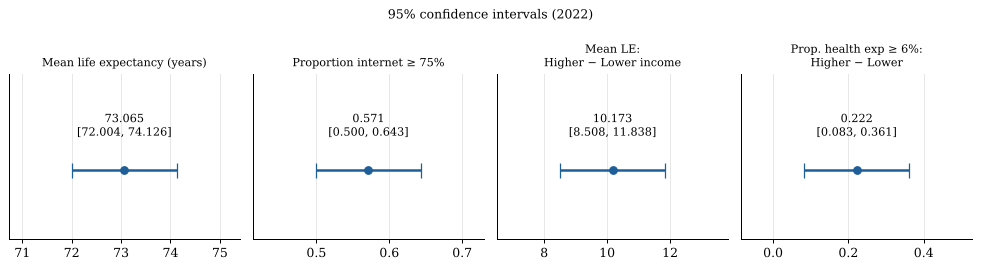

In [27]:
# Figure 8: the four intervals (separate panels because units differ)
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, (name, row) in zip(axes, ci.iterrows()):
    ax.errorbar(row["estimate"], 0, xerr=[[row["estimate"] - row["95% lower"]], [row["95% upper"] - row["estimate"]]],
                fmt="o", color=BLUE, capsize=6, lw=2)
    ax.set_yticks([]); ax.set_title(name.replace(": ", ":\n"), fontsize=9)
    ax.text(row["estimate"], 0.25, f"{row['estimate']:.3f}\n[{row['95% lower']:.3f}, {row['95% upper']:.3f}]",
            ha="center", fontsize=9); ax.set_ylim(-0.5, 0.7)
    lo, hi = row["95% lower"], row["95% upper"]; pad = (hi - lo) * 0.6
    ax.set_xlim(lo - pad, hi + pad)
fig.suptitle("95% confidence intervals (2022)", fontsize=10)
fig.tight_layout(); fig.savefig("figures/fig8_confidence_intervals.png"); plt.show()

## 7. Outputs supporting the critical reflection (Task 3)

Checks of the assumptions behind the methods above.

In [28]:
# (a) Independence over time: share of countries with rising life expectancy by year (COVID shock)
by_year = inc.mean()
print("Share of countries with rising LE, by year-pair:\n", by_year.round(3).to_string())

# (b) Normality: Shapiro-Wilk for the variables used in t-intervals
for name, s_ in [("life_exp (all)", le), ("life_exp Higher-income", a), ("life_exp Lower-income", b)]:
    print(f"Shapiro-Wilk {name}: W = {stats.shapiro(s_).statistic:.3f}, p = {stats.shapiro(s_).pvalue:.3g}")

# (c) Population vs sample: the 'sample' is (almost) every country, so the CI quantifies a hypothetical
# super-population; the finite population correction shows how much the SE would shrink
N_pop = len(df22); fpc = np.sqrt((N_pop - n1) / (N_pop - 1))
print(f"Countries with LE data {n1} of {N_pop}; finite-population correction factor = {fpc:.3f}")

# (d) Unweighted means treat Tuvalu like India: compare with population-weighted mean is not possible
# without population data, but the median-mean gap shows the influence of small, skewed units
print(f"Mean vs median GDP pc: {df22['gdp_pc'].mean():,.0f} vs {df22['gdp_pc'].median():,.0f}")

# (e) Missingness is not random: internet data are more often missing for which group?
miss_int = df22.assign(miss=df22["internet"].isna()).groupby("income_grp")["miss"].mean()
print("Share missing internet data by group:\n", miss_int.round(3).to_string())

Share of countries with rising LE, by year-pair:
 year
2016   0.8440
2017   0.8120
2018   0.8810
2019   0.8580
2020   0.2980
2021   0.2800
2022   0.8760
Shapiro-Wilk life_exp (all): W = 0.896, p = 4.01e-11
Shapiro-Wilk life_exp Higher-income: W = 0.954, p = 0.00113
Shapiro-Wilk life_exp Lower-income: W = 0.795, p = 8.89e-11
Countries with LE data 218 of 218; finite-population correction factor = 0.000
Mean vs median GDP pc: 21,110 vs 7,631
Share missing internet data by group:
 income_grp
Higher-income   0.1520
Lower-income    0.1240


In [29]:
# List of exported files for the report
for folder in ["figures", "results"]:
    print(folder, sorted(f for f in os.listdir(folder) if f.endswith(".png")))

figures ['fig1_hist_life_expectancy.png', 'fig2_hist_gdp_raw_vs_log.png', 'fig3_scatter_loggdp_life_exp.png', 'fig4_boxplot_life_exp_by_group.png', 'fig5_correlation_matrix.png', 'fig6_pmf_discrete.png', 'fig7_qq_plots.png', 'fig8_confidence_intervals.png']
results ['tab0_missing.png', 'tab1_vectors.png', 'tab2a_XtX.png', 'tab2b_corr.png', 'tab2c_determinant.png', 'tab2d_normal_eq.png', 'tab3_descriptives.png', 'tab4a_discrete.png', 'tab4b_continuous.png', 'tab5_confidence_intervals.png']
